In [1]:
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.mixture import GaussianMixture
from scipy.stats import gamma as gamma_dist
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from pathlib import Path

/Users/angelaliu/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
base_dir      = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP")
transport_dir = base_dir / "Updated Code" / "transport narrowed param ranges"
mat_path = transport_dir / "all_trial_bkt_data.mat"

In [3]:
# Reused unchanged from GammaMixture.ipynb — do not duplicate/diverge, keep in sync if that
# notebook's loader/fit function changes.
def load_all_trial_bkt_data(mat_path, ps_indices=None):
    param_sets = {}
    with h5py.File(mat_path, 'r') as f:
        weights = f['weights'][()].T  # (num_param_sets, 3)
        atbd = f['all_trial_bkt_data']  # (1, N) object refs
        indices = ps_indices if ps_indices is not None else range(atbd.shape[1])
        for i in indices:
            ps_grp = f[atbd[0, i]]
            p0 = float(ps_grp['p0'][()].flat[0])
            td = ps_grp['trial_data']  # (1, num_trials) object refs
            trial_data = []
            for j in range(td.shape[1]):
                arr = f[td[0, j]][()]
                if arr.dtype == np.float64:
                    trial_data.append(arr.flatten())
                else:
                    trial_data.append(np.array([], dtype=np.float64))
            param_sets[i] = {'p0': p0, 'trial_data': trial_data}
    return param_sets, weights


def recover_theta(w):
    disc = 1*w[0] + 2.1*(1 - w[0])       # [1, 2.1]
    b    = 0.01e-3*w[1] + 0.3e-3*(1 - w[1])  # [0.01e-3, 0.3e-3]
    lr   = 0.3*w[2] + 0.5*(1 - w[2])     # [0.3, 0.5]
    return disc, lr, b


def fit_gamma_mixture(bkt_samples, n_init=5, seed=0):
    """Fit a 2-component gamma mixture via MLE. Returns dict with
    w1, alpha1, beta1, alpha2, beta2, nll, or None if <5 samples."""
    t = np.asarray(bkt_samples, dtype=float)
    t = t[np.isfinite(t) & (t > 0)]
    if len(t) < 5:
        return None
    rng = np.random.default_rng(seed)

    def neg_log_lik(params):
        w1_raw, la1, ls1, la2, ls2 = params
        w1 = 1.0 / (1.0 + np.exp(-np.clip(w1_raw, -20, 20)))
        a1, s1 = np.exp(np.clip(la1, -10, 15)), np.exp(np.clip(ls1, -10, 30))
        a2, s2 = np.exp(np.clip(la2, -10, 15)), np.exp(np.clip(ls2, -10, 30))
        pdf = w1 * gamma_dist.pdf(t, a=a1, scale=s1) + (1.0 - w1) * gamma_dist.pdf(t, a=a2, scale=s2)
        return -np.sum(np.log(np.clip(pdf, 1e-300, None)))

    def mom(x):
        m, v = np.mean(x), np.var(x)
        if v < 1e-30:
            v = m ** 2 * 0.1
        return max(m ** 2 / v, 0.1), max(v / m, 1e-10)

    best_res, best_nll = None, np.inf
    for _ in range(n_init):
        q = rng.uniform(0.15, 0.85)
        split = np.quantile(t, q)
        t_lo = t[t <= split] if np.any(t <= split) else t
        t_hi = t[t > split] if np.any(t > split) else t
        a1_0, s1_0 = mom(t_lo)
        a2_0, s2_0 = mom(t_hi)
        w0 = np.clip(len(t_lo) / len(t), 1e-4, 1 - 1e-4)
        x0 = [np.log(w0 / (1 - w0)), np.log(a1_0), np.log(s1_0), np.log(a2_0), np.log(s2_0)]
        try:
            res = minimize(neg_log_lik, x0, method='Nelder-Mead',
                            options={'maxiter': 5000, 'xatol': 1e-6, 'fatol': 1e-6, 'adaptive': True})
            if res.fun < best_nll:
                best_res, best_nll = res, res.fun
        except Exception:
            continue

    if best_res is None:
        return None

    w1_raw, la1, ls1, la2, ls2 = best_res.x
    w1 = 1.0 / (1.0 + np.exp(-np.clip(w1_raw, -20, 20)))
    a1, s1 = np.exp(np.clip(la1, -10, 15)), np.exp(np.clip(ls1, -10, 30))
    a2, s2 = np.exp(np.clip(la2, -10, 15)), np.exp(np.clip(ls2, -10, 30))
    if a1 * s1 > a2 * s2:
        w1, a1, s1, a2, s2 = 1.0 - w1, a2, s2, a1, s1

    return {'w1': float(w1), 'alpha1': float(a1), 'beta1': float(s1),
            'alpha2': float(a2), 'beta2': float(s2), 'nll': float(best_nll)}

In [4]:
# Identify usable (well-connected) param sets. Ranges were narrowed for this
# sweep ([1,2.1] disc, [0.3,0.5] length_ratio -- length_ratio in particular was
# found to gate connectivity almost entirely in the earlier 20-param-set run)
# specifically to raise the yield of usable param sets vs. that earlier run's
# ~30%. USABLE_PS below is chosen to keep a reasonable amount of connected-trial
# data per group; adjust the threshold if the actual yield differs.
P0_THRESHOLD = 0.9
MAX_TRIALS_PER_PS = 150  # cap per param set; lowered from 400 now that there
                          # are ~120 param sets instead of 6 -- 150 was already
                          # ample resolution per theta point in the prototype

with h5py.File(mat_path, 'r') as f:
    n_param_sets = f['all_trial_bkt_data'].shape[1]

all_param_sets, weights = load_all_trial_bkt_data(mat_path, range(n_param_sets))
USABLE_PS = sorted(i for i, ps in all_param_sets.items() if ps['p0'] < P0_THRESHOLD)
print(f"{len(USABLE_PS)} / {n_param_sets} param sets usable (p0 < {P0_THRESHOLD}):")
for i in USABLE_PS:
    print(f"  param set {i}: p0={all_param_sets[i]['p0']:.3f}")

87 / 120 param sets usable (p0 < 0.9):
  param set 0: p0=0.881
  param set 2: p0=0.880
  param set 3: p0=0.163
  param set 4: p0=0.416
  param set 5: p0=0.041
  param set 6: p0=0.136
  param set 7: p0=0.870
  param set 8: p0=0.003
  param set 10: p0=0.760
  param set 12: p0=0.186
  param set 14: p0=0.326
  param set 15: p0=0.531
  param set 17: p0=0.169
  param set 19: p0=0.729
  param set 20: p0=0.821
  param set 21: p0=0.655
  param set 22: p0=0.003
  param set 23: p0=0.013
  param set 24: p0=0.469
  param set 25: p0=0.741
  param set 27: p0=0.405
  param set 28: p0=0.014
  param set 29: p0=0.069
  param set 30: p0=0.879
  param set 31: p0=0.031
  param set 33: p0=0.269
  param set 35: p0=0.179
  param set 37: p0=0.391
  param set 38: p0=0.281
  param set 40: p0=0.724
  param set 43: p0=0.620
  param set 44: p0=0.781
  param set 45: p0=0.274
  param set 46: p0=0.899
  param set 47: p0=0.581
  param set 48: p0=0.535
  param set 49: p0=0.186
  param set 50: p0=0.249
  param set 51: p0=

In [5]:
# Fit gamma mixtures over ALL connected trials (capped at MAX_TRIALS_PER_PS) for
# each usable param set. At ~100+ usable param sets this is no longer cheap
# enough to run serially (100 x 150 x ~0.5s/fit ~ 2 hours) -- parallelize
# across trials with a process pool. Explicitly use the 'fork' start method:
# the default 'spawn' context on macOS can't pickle functions defined in a
# notebook's __main__ namespace, which fit_gamma_mixture is.
import multiprocessing
from concurrent.futures import ProcessPoolExecutor

_fork_ctx = multiprocessing.get_context('fork')


def _fit_gamma_mixture_seeded(bkt, seed):
    return fit_gamma_mixture(bkt, seed=seed)

records = []
for ps_idx in USABLE_PS:
    ps = all_param_sets[ps_idx]
    disc, lr, b = recover_theta(weights[ps_idx])
    connected_trial_idxs = [j for j, bkt in enumerate(ps['trial_data']) if len(bkt) > 0]
    rng = np.random.default_rng(ps_idx)
    if len(connected_trial_idxs) > MAX_TRIALS_PER_PS:
        connected_trial_idxs = list(rng.choice(connected_trial_idxs, size=MAX_TRIALS_PER_PS, replace=False))

    bkts = [ps['trial_data'][tr_idx] for tr_idx in connected_trial_idxs]
    with ProcessPoolExecutor(mp_context=_fork_ctx) as executor:
        fits = list(executor.map(_fit_gamma_mixture_seeded, bkts, connected_trial_idxs))

    n_done = 0
    for tr_idx, fit in zip(connected_trial_idxs, fits):
        if fit is None:
            continue
        records.append({
            'paramset_idx': ps_idx,
            'discspacing': disc, 'length_ratio': lr, 'b': b,
            'p0': ps['p0'], 'trial_idx': tr_idx,
            **fit,
        })
        n_done += 1
    print(f"param set {ps_idx}: {n_done}/{len(connected_trial_idxs)} fits done")

df = pd.DataFrame(records)
print(f"\nTotal: {len(df)} fit records across {df['paramset_idx'].nunique()} param sets")

param set 0: 119/119 fits done
param set 2: 120/120 fits done
param set 3: 150/150 fits done
param set 4: 150/150 fits done
param set 5: 150/150 fits done
param set 6: 150/150 fits done
param set 7: 130/130 fits done
param set 8: 150/150 fits done
param set 10: 150/150 fits done
param set 12: 150/150 fits done
param set 14: 150/150 fits done
param set 15: 150/150 fits done
param set 17: 150/150 fits done
param set 19: 150/150 fits done
param set 20: 150/150 fits done
param set 21: 150/150 fits done
param set 22: 150/150 fits done
param set 23: 150/150 fits done
param set 24: 150/150 fits done
param set 25: 150/150 fits done
param set 27: 150/150 fits done
param set 28: 150/150 fits done
param set 29: 150/150 fits done
param set 30: 121/121 fits done
param set 31: 150/150 fits done
param set 33: 150/150 fits done
param set 35: 150/150 fits done
param set 37: 150/150 fits done
param set 38: 150/150 fits done
param set 40: 150/150 fits done
param set 43: 150/150 fits done
param set 44: 15

In [6]:
# Degenerate-fit check: does w1 pile up near 0/1 (component collapse), and do
# alpha2/beta2 show the extreme spread expected when the 2nd component carries
# very little mixture weight (and is therefore poorly identified)?
print("w1:\n", df['w1'].describe())
print("\nalpha2:\n", df['alpha2'].describe())
print("\nbeta2:\n", df['beta2'].describe())
# Expect: median w1 well above 0.5 (component 1 dominant), and alpha2/beta2
# spanning many orders of magnitude -- this is a known symptom of a
# poorly-identified 2nd component when it carries little weight, not a fitting
# bug. We keep these fits (log-transform handles the scale spread) rather than
# filtering, but flag this as a data-quality caveat on the coefficients
# themselves, separate from the sample-size problem below.

w1:
 count    1.270600e+04
mean     7.368968e-01
std      2.447979e-01
min      2.061154e-09
25%      5.796988e-01
50%      8.209733e-01
75%      9.413870e-01
max      1.000000e+00
Name: w1, dtype: float64

alpha2:
 count    1.270600e+04
mean     4.141831e+04
std      3.549843e+05
min      4.539993e-05
25%      3.100197e+00
50%      9.900260e+00
75%      3.381009e+01
max      3.269017e+06
Name: alpha2, dtype: float64

beta2:
 count    1.270600e+04
mean     7.582345e+09
std      2.843247e+11
min      4.539993e-05
25%      9.499735e+03
50%      6.422115e+04
75%      4.939710e+05
max      1.068647e+13
Name: beta2, dtype: float64


In [7]:
COEF_NAMES = ['w1', 'alpha1', 'beta1', 'alpha2', 'beta2']
D = 5


def to_y(row):
    w1 = np.clip(row['w1'], 1e-4, 1 - 1e-4)
    return np.array([
        np.log(w1 / (1 - w1)),
        np.log(row['alpha1']), np.log(row['beta1']),
        np.log(row['alpha2']), np.log(row['beta2']),
    ], dtype=np.float64)


df['y'] = df.apply(to_y, axis=1)

groups = sorted(df['paramset_idx'].unique())
theta_by_group = {g: df[df['paramset_idx'] == g][['discspacing', 'length_ratio', 'b']].iloc[0].values for g in groups}
theta_unique = np.stack(list(theta_by_group.values()))
theta_mean, theta_std = theta_unique.mean(axis=0), theta_unique.std(axis=0)
theta_std[theta_std == 0] = 1.0


def standardize(theta):
    return (theta - theta_mean) / theta_std

In [8]:
# MDN: shared MLP backbone -> K Gaussian components over the 5-D y space,
# FULL covariance per component (via Cholesky factor L, built from a positive
# diagonal + free off-diagonal entries) -- diagonal-only covariance would
# misrepresent the alpha/beta trade-off ridge within each gamma component
# (see plan notes). K is left tunable rather than hardcoded.
def build_mdn(K):
    N_TRIL_OFF = D * (D - 1) // 2
    tril_off_i, tril_off_j = np.tril_indices(D, k=-1)
    E = np.zeros((N_TRIL_OFF, D * D), dtype=np.float32)
    for p, (i, j) in enumerate(zip(tril_off_i, tril_off_j)):
        E[p, i * D + j] = 1.0
    E = tf.constant(E)
    N_OUT = K * (1 + D + D + N_TRIL_OFF)

    def unpack(raw):
        idx = K
        means = tf.reshape(raw[:, idx:idx + K * D], (-1, K, D)); idx += K * D
        diag_raw = tf.reshape(raw[:, idx:idx + K * D], (-1, K, D)); idx += K * D
        offdiag_raw = tf.reshape(raw[:, idx:idx + K * N_TRIL_OFF], (-1, K, N_TRIL_OFF))
        return raw[:, 0:K], means, diag_raw, offdiag_raw

    def build_L(diag_raw, offdiag_raw):
        diag = tf.nn.softplus(diag_raw) + 1e-4
        L = tf.linalg.diag(diag)
        offdiag_flat = tf.tensordot(offdiag_raw, E, axes=[[2], [0]])
        offdiag_full = tf.reshape(offdiag_flat, tf.shape(L))
        return L + offdiag_full, diag

    def nll(y_true, raw):
        logits, means, diag_raw, offdiag_raw = unpack(raw)
        L, diag = build_L(diag_raw, offdiag_raw)
        diff = tf.expand_dims(y_true, 1) - means
        diff = tf.expand_dims(diff, -1)
        z = tf.squeeze(tf.linalg.triangular_solve(L, diff, lower=True), -1)
        log_det = tf.reduce_sum(tf.math.log(diag), axis=-1)
        quad = tf.reduce_sum(tf.square(z), axis=-1)
        log_comp = -0.5 * D * tf.math.log(2 * np.pi) - log_det - 0.5 * quad
        log_mix = tf.nn.log_softmax(logits, axis=-1)
        return -tf.reduce_mean(tf.reduce_logsumexp(log_mix + log_comp, axis=-1))

    inp = keras.Input(shape=(3,))
    h = keras.layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(inp)
    h = keras.layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(h)
    out = keras.layers.Dense(N_OUT)(h)
    model = keras.Model(inp, out)

    class MDNLoss(keras.losses.Loss):
        def call(self, y_true, y_pred):
            return nll(y_true, y_pred)

    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=MDNLoss())
    return model, unpack, build_L


def per_sample_nll(raw, y, unpack, build_L):
    logits, means, diag_raw, offdiag_raw = unpack(raw)
    L, diag = build_L(diag_raw, offdiag_raw)
    diff = tf.expand_dims(y, 1) - means
    diff = tf.expand_dims(diff, -1)
    z = tf.squeeze(tf.linalg.triangular_solve(L, diff, lower=True), -1)
    log_det = tf.reduce_sum(tf.math.log(diag), axis=-1)
    quad = tf.reduce_sum(tf.square(z), axis=-1)
    log_comp = -0.5 * D * tf.math.log(2 * np.pi) - log_det - 0.5 * quad
    log_mix = tf.nn.log_softmax(logits, axis=-1)
    return -tf.reduce_logsumexp(log_mix + log_comp, axis=-1).numpy()

In [9]:
# Leave-one-param-set-out CV, for K in {1,2,3}. With only ~6 distinct theta
# groups, in-sample fit would be close to meaningless (the model can just
# memorize); this is the real test of whether conditioning on theta helps at
# all yet. Compared against a pooled, theta-BLIND Gaussian-mixture baseline
# fit to the other groups' y samples -- if the conditioned model can't beat
# this, theta isn't helping given current data volume.
results = {}
for K in [1, 2, 3]:
    fold_model_nlls, fold_baseline_nlls, fold_ns = [], [], []
    for held_out in groups:
        train_df = df[df['paramset_idx'] != held_out]
        test_df = df[df['paramset_idx'] == held_out]

        theta_train = standardize(train_df[['discspacing', 'length_ratio', 'b']].values.astype(np.float64)).astype(np.float32)
        y_train = np.stack(train_df['y'].values).astype(np.float32)
        theta_test = standardize(test_df[['discspacing', 'length_ratio', 'b']].values.astype(np.float64)).astype(np.float32)
        y_test = np.stack(test_df['y'].values).astype(np.float32)

        model, unpack, build_L = build_mdn(K)
        model.fit(theta_train, y_train, epochs=300, batch_size=64, verbose=0)

        raw_test = model.predict(theta_test, verbose=0)
        nlls = per_sample_nll(raw_test, tf.constant(y_test), unpack, build_L)
        fold_model_nlls.append(np.mean(nlls))

        gmm = GaussianMixture(n_components=K, covariance_type='full', random_state=0, reg_covar=1e-6)
        gmm.fit(y_train)
        fold_baseline_nlls.append(-gmm.score_samples(y_test).mean())
        fold_ns.append(len(test_df))

        print(f"K={K} held_out=ps{held_out} n={len(test_df):4d}  "
              f"model_NLL={fold_model_nlls[-1]:.3f}  baseline_NLL={fold_baseline_nlls[-1]:.3f}")

    results[K] = {
        'model_nll': np.average(fold_model_nlls, weights=fold_ns),
        'baseline_nll': np.average(fold_baseline_nlls, weights=fold_ns),
    }

print("\n=== summary (sample-weighted avg held-out NLL, lower=better) ===")
for K, r in results.items():
    verdict = 'beats' if r['model_nll'] < r['baseline_nll'] else 'does NOT beat'
    print(f"K={K}: model={r['model_nll']:.3f}  pooled_baseline={r['baseline_nll']:.3f}  (model {verdict} baseline)")

K=1 held_out=ps0 n= 119  model_NLL=8.398  baseline_NLL=9.734
K=1 held_out=ps2 n= 120  model_NLL=10.382  baseline_NLL=10.887
K=1 held_out=ps3 n= 150  model_NLL=6.874  baseline_NLL=8.978
K=1 held_out=ps4 n= 150  model_NLL=9.945  baseline_NLL=11.492
K=1 held_out=ps5 n= 150  model_NLL=5.734  baseline_NLL=8.296
K=1 held_out=ps6 n= 150  model_NLL=7.185  baseline_NLL=8.838
K=1 held_out=ps7 n= 130  model_NLL=2163.581  baseline_NLL=23.410
K=1 held_out=ps8 n= 150  model_NLL=5.585  baseline_NLL=8.485
K=1 held_out=ps10 n= 150  model_NLL=13.772  baseline_NLL=11.734
K=1 held_out=ps12 n= 150  model_NLL=6.717  baseline_NLL=8.819
K=1 held_out=ps14 n= 150  model_NLL=6.416  baseline_NLL=10.589
K=1 held_out=ps15 n= 150  model_NLL=6.470  baseline_NLL=8.620
K=1 held_out=ps17 n= 150  model_NLL=7.419  baseline_NLL=9.685
K=1 held_out=ps19 n= 150  model_NLL=13.849  baseline_NLL=14.958
K=1 held_out=ps20 n= 150  model_NLL=8.705  baseline_NLL=9.915
K=1 held_out=ps21 n= 150  model_NLL=6.801  baseline_NLL=9.212
K=1 

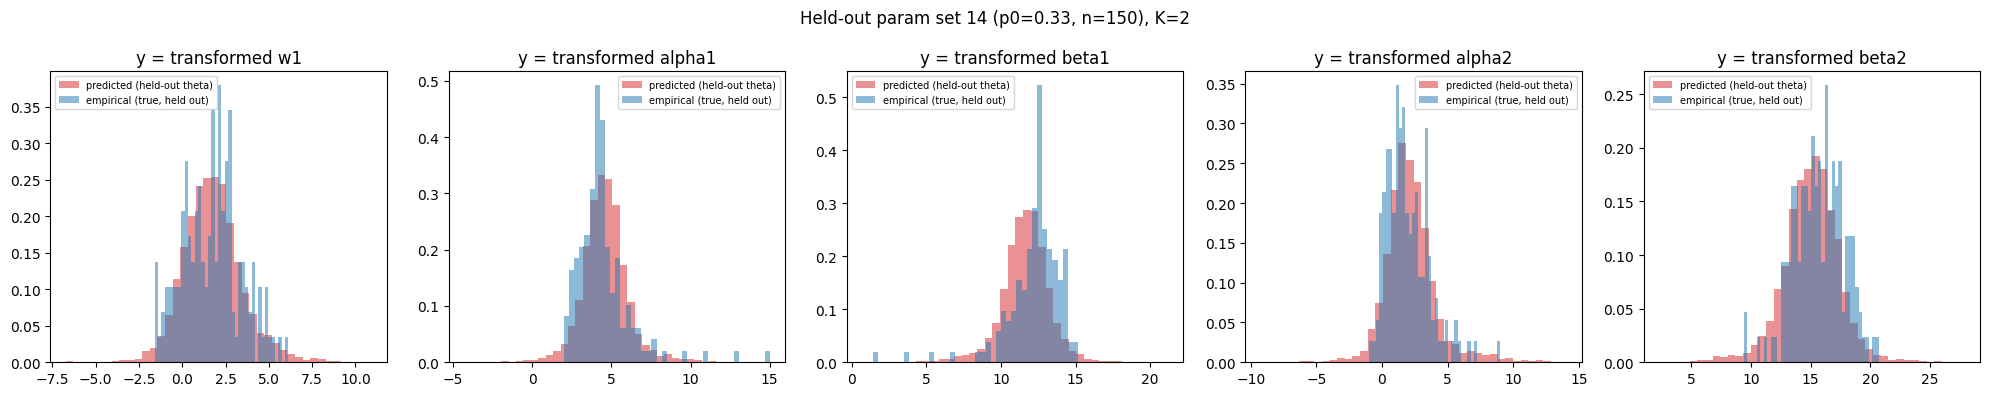

In [10]:
# Visual check for the best-connected held-out group (param set 14, p0~0.13,
# ~400 sampled trials) -- the one case where the model/baseline gap was
# smallest, so the comparison is least noise-dominated.
BEST_K = 2
HELD_OUT_PS = 14

train_df = df[df['paramset_idx'] != HELD_OUT_PS]
test_df = df[df['paramset_idx'] == HELD_OUT_PS]
theta_train = standardize(train_df[['discspacing', 'length_ratio', 'b']].values.astype(np.float64)).astype(np.float32)
y_train = np.stack(train_df['y'].values).astype(np.float32)
theta_test = standardize(test_df[['discspacing', 'length_ratio', 'b']].values.astype(np.float64)).astype(np.float32)
y_test = np.stack(test_df['y'].values).astype(np.float32)

model, unpack, build_L = build_mdn(BEST_K)
model.fit(theta_train, y_train, epochs=300, batch_size=64, verbose=0)

raw = model.predict(theta_test[:1], verbose=0)
logits, means, diag_raw, offdiag_raw = unpack(raw)
L, diag = build_L(diag_raw, offdiag_raw)
mix = tf.nn.softmax(logits, axis=-1).numpy()[0]
means_np = means.numpy()[0]
L_np = L.numpy()[0]

rng = np.random.default_rng(0)
n_sample = 5000
comp_choice = rng.choice(BEST_K, size=n_sample, p=mix)
samples = np.zeros((n_sample, D))
for k in range(BEST_K):
    idx = comp_choice == k
    z = rng.normal(size=(idx.sum(), D))
    samples[idx] = means_np[k] + z @ L_np[k].T

fig, axes = plt.subplots(1, D, figsize=(4 * D, 4))
for i, name in enumerate(COEF_NAMES):
    ax = axes[i]
    ax.hist(samples[:, i], bins=40, density=True, alpha=0.5, label='predicted (held-out theta)', color='tab:red')
    ax.hist(y_test[:, i], bins=40, density=True, alpha=0.5, label='empirical (true, held out)', color='tab:blue')
    ax.set_title(f'y = transformed {name}')
    ax.legend(fontsize=7)
plt.suptitle(f'Held-out param set {HELD_OUT_PS} (p0={test_df["p0"].iloc[0]:.2f}, n={len(test_df)}), K={BEST_K}')
plt.tight_layout()
plt.savefig(transport_dir / f'MDN_heldout_ps{HELD_OUT_PS}_K{BEST_K}.png', dpi=150)
plt.show()

True (held-out) correlation matrix:
          w1  alpha1  beta1  alpha2  beta2
w1      1.00   -0.61   0.62   -0.21   0.39
alpha1 -0.61    1.00  -1.00    0.31  -0.42
beta1   0.62   -1.00   1.00   -0.32   0.44
alpha2 -0.21    0.31  -0.32    1.00  -0.95
beta2   0.39   -0.42   0.44   -0.95   1.00

Predicted correlation matrix:
          w1  alpha1  beta1  alpha2  beta2
w1      1.00   -0.67   0.67    0.01   0.19
alpha1 -0.67    1.00  -0.99    0.19  -0.36
beta1   0.67   -0.99   1.00   -0.19   0.37
alpha2  0.01    0.19  -0.19    1.00  -0.94
beta2   0.19   -0.36   0.37   -0.94   1.00

Difference (predicted - true), large values = correlation structure not captured:
          w1  alpha1  beta1  alpha2  beta2
w1      0.00   -0.06   0.05    0.23  -0.20
alpha1 -0.06    0.00   0.00   -0.12   0.06
beta1   0.05    0.00   0.00    0.13  -0.07
alpha2  0.23   -0.12   0.13   -0.00   0.01
beta2  -0.20    0.06  -0.07    0.01   0.00


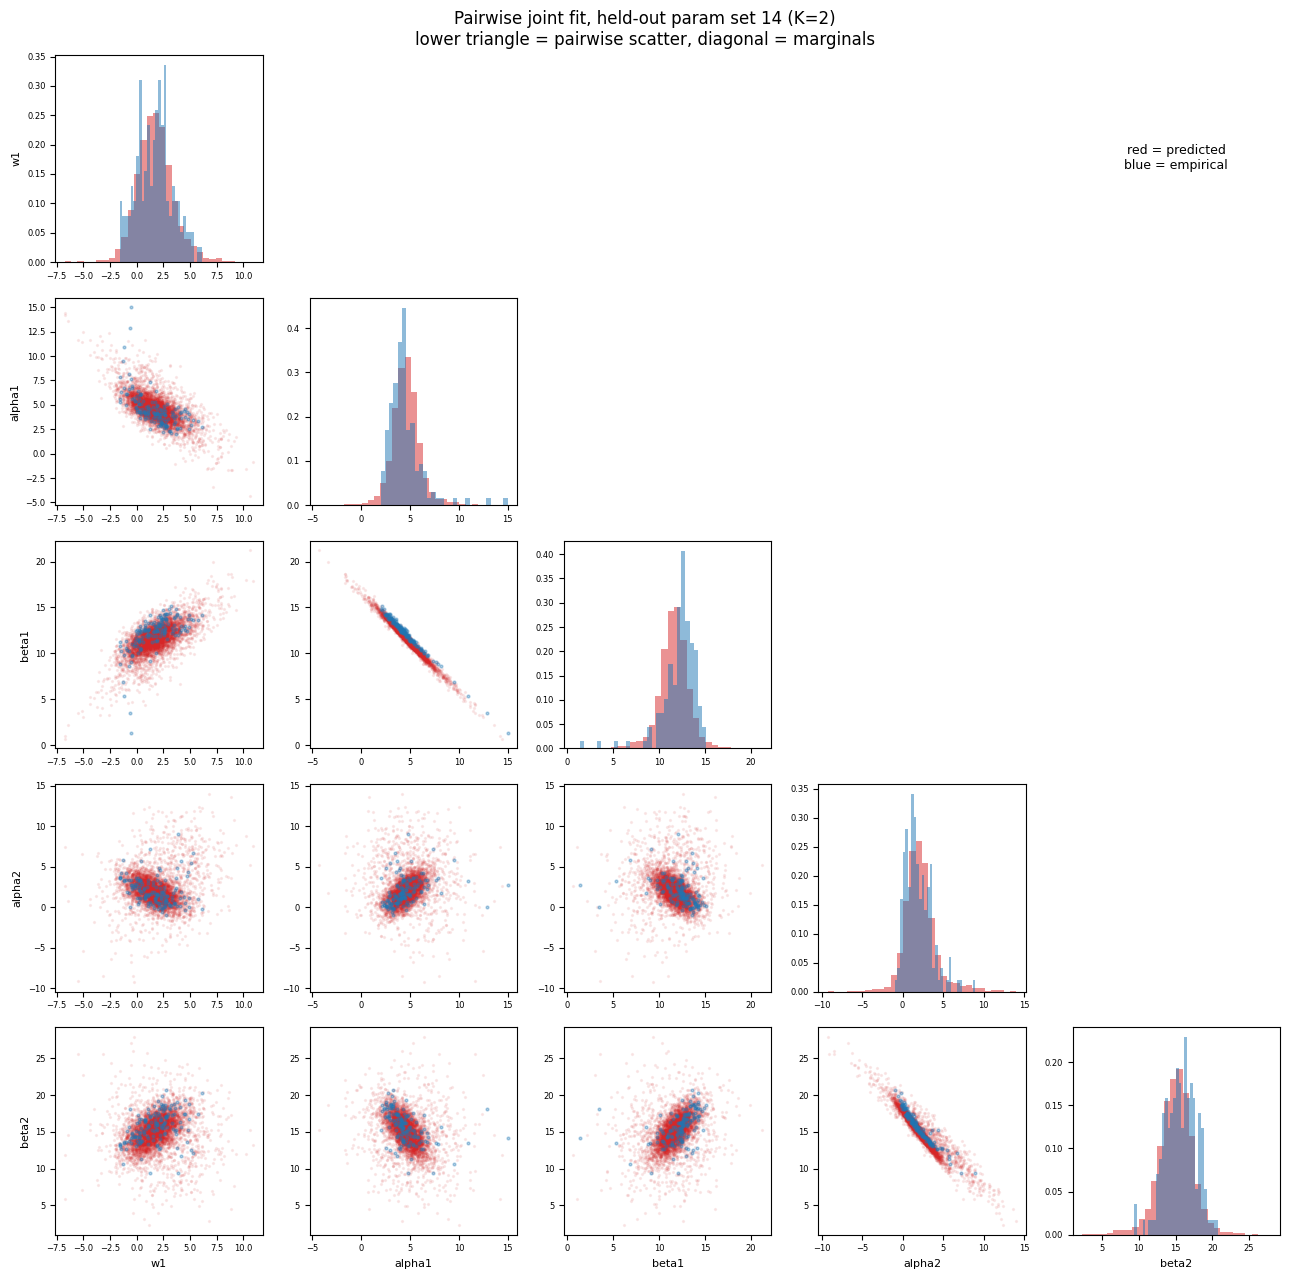

In [12]:
# Joint-fit diagnostics for the held-out group above. The marginal histograms
# in the previous cell only check each coefficient independently -- they can
# look fine even if the model gets cross-coefficient correlations wrong (e.g.
# the alpha/beta trade-off ridge within a gamma component). Two joint-aware
# checks:
#
# 1. Held-out NLL (cell 8) is already a genuine joint metric -- it's the
#    log-density of the true 5-D points under the full fitted mixture,
#    correlations included, not decomposable into per-coefficient terms. The
#    model-vs-baseline NLL comparison there is the real evaluation; this cell
#    is a way to *see* what that number is summarizing, not a replacement.
#
# 2. Below: a correlation-matrix comparison, and a pairwise (corner-plot
#    style) scatter of predicted vs. true samples for every coefficient pair.

true_corr = np.corrcoef(y_test, rowvar=False)
pred_corr = np.corrcoef(samples, rowvar=False)

print("True (held-out) correlation matrix:")
print(pd.DataFrame(true_corr, index=COEF_NAMES, columns=COEF_NAMES).round(2))
print("\nPredicted correlation matrix:")
print(pd.DataFrame(pred_corr, index=COEF_NAMES, columns=COEF_NAMES).round(2))
print("\nDifference (predicted - true), large values = correlation structure not captured:")
print(pd.DataFrame(pred_corr - true_corr, index=COEF_NAMES, columns=COEF_NAMES).round(2))

fig, axes = plt.subplots(D, D, figsize=(2.6 * D, 2.6 * D))
for i in range(D):
    for j in range(D):
        ax = axes[i, j]
        if i == j:
            ax.hist(samples[:, i], bins=30, density=True, alpha=0.5, color='tab:red')
            ax.hist(y_test[:, i], bins=30, density=True, alpha=0.5, color='tab:blue')
        elif i > j:
            ax.scatter(samples[:, j], samples[:, i], s=2, alpha=0.08, color='tab:red', label='predicted')
            ax.scatter(y_test[:, j], y_test[:, i], s=4, alpha=0.35, color='tab:blue', label='empirical (true)')
        else:
            ax.axis('off')
            if i == 0 and j == D - 1:
                ax.text(0.5, 0.5, 'red = predicted\nblue = empirical', ha='center', va='center',
                        transform=ax.transAxes, fontsize=9)
        if i == D - 1:
            ax.set_xlabel(COEF_NAMES[j], fontsize=8)
        if j == 0:
            ax.set_ylabel(COEF_NAMES[i], fontsize=8)
        ax.tick_params(labelsize=6)

plt.suptitle(f'Pairwise joint fit, held-out param set {HELD_OUT_PS} (K={BEST_K})\n'
             f'lower triangle = pairwise scatter, diagonal = marginals')
plt.tight_layout()
plt.savefig(transport_dir / f'MDN_heldout_ps{HELD_OUT_PS}_K{BEST_K}_pairwise.png', dpi=150)
plt.show()

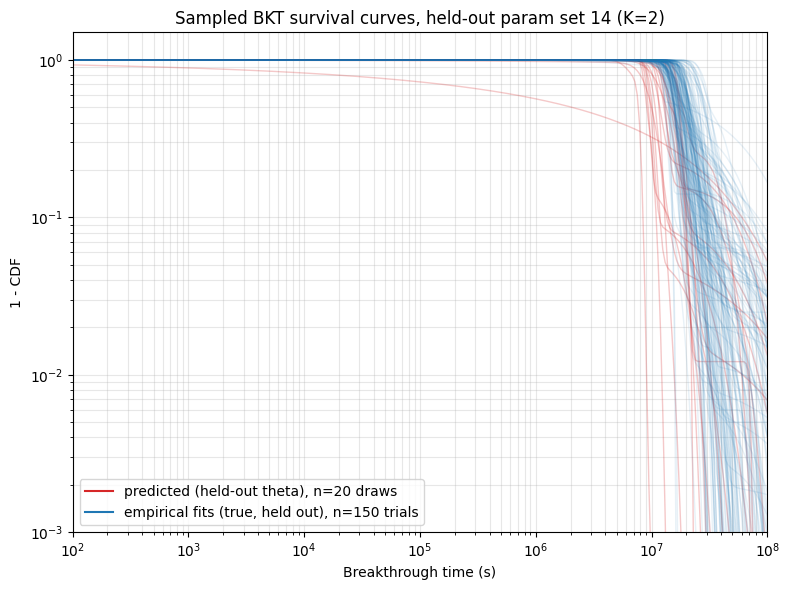

In [15]:
# Turn sampled (w1,alpha1,beta1,alpha2,beta2) tuples back into actual BKT
# survival curves (1-CDF, same convention as GammaMixture.ipynb) -- the most
# direct, physically-interpretable check of the joint fit: does the *shape*
# of curves implied by predicted coefficient draws look like the shape of
# curves fit to the real held-out trials?

def survival(t, w1, a1, b1, a2, b2):
    return (w1 * (1 - gamma_dist.cdf(t, a=a1, scale=b1)) +
            (1 - w1) * (1 - gamma_dist.cdf(t, a=a2, scale=b2)))

N_CURVES_PRED = 20  # predicted draws are cheap/unlimited, keep this modest to avoid clutter
t_grid = np.logspace(2, 8, 300)

# predicted: inverse-transform a random subset of the mixture samples drawn above
rng2 = np.random.default_rng(1)
pred_idx = rng2.choice(len(samples), size=min(N_CURVES_PRED, len(samples)), replace=False)
pred_coefs = samples[pred_idx]  # still in y-space: [logit(w1), log(a1), log(b1), log(a2), log(b2)]

# empirical: ALL of the actual per-trial MLE fits for the held-out param set
# (not subsampled -- there are only as many as connected trials, capped at
# MAX_TRIALS_PER_PS, so plotting all of them is the real empirical spread)
emp_coefs = test_df[COEF_NAMES].values

fig, ax = plt.subplots(figsize=(8, 6))

for y in pred_coefs:
    w1, a1, b1, a2, b2 = (1 / (1 + np.exp(-y[0])), np.exp(y[1]), np.exp(y[2]), np.exp(y[3]), np.exp(y[4]))
    ax.loglog(t_grid, survival(t_grid, w1, a1, b1, a2, b2), color='tab:red', alpha=0.25, lw=1)

emp_alpha = max(0.05, min(0.35, 15.0 / len(emp_coefs)))
for w1, a1, b1, a2, b2 in emp_coefs:
    ax.loglog(t_grid, survival(t_grid, w1, a1, b1, a2, b2), color='tab:blue', alpha=emp_alpha, lw=1)

ax.plot([], [], color='tab:red', label=f'predicted (held-out theta), n={len(pred_coefs)} draws')
ax.plot([], [], color='tab:blue', label=f'empirical fits (true, held out), n={len(emp_coefs)} trials')
ax.set_xlim(t_grid[0], t_grid[-1])
ax.set_ylim(1e-3, 1.5)
ax.set_xlabel('Breakthrough time (s)')
ax.set_ylabel('1 - CDF')
ax.set_title(f'Sampled BKT survival curves, held-out param set {HELD_OUT_PS} (K={BEST_K})')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig(transport_dir / f'MDN_heldout_ps{HELD_OUT_PS}_K{BEST_K}_bkt_curves.png', dpi=150)
plt.show()

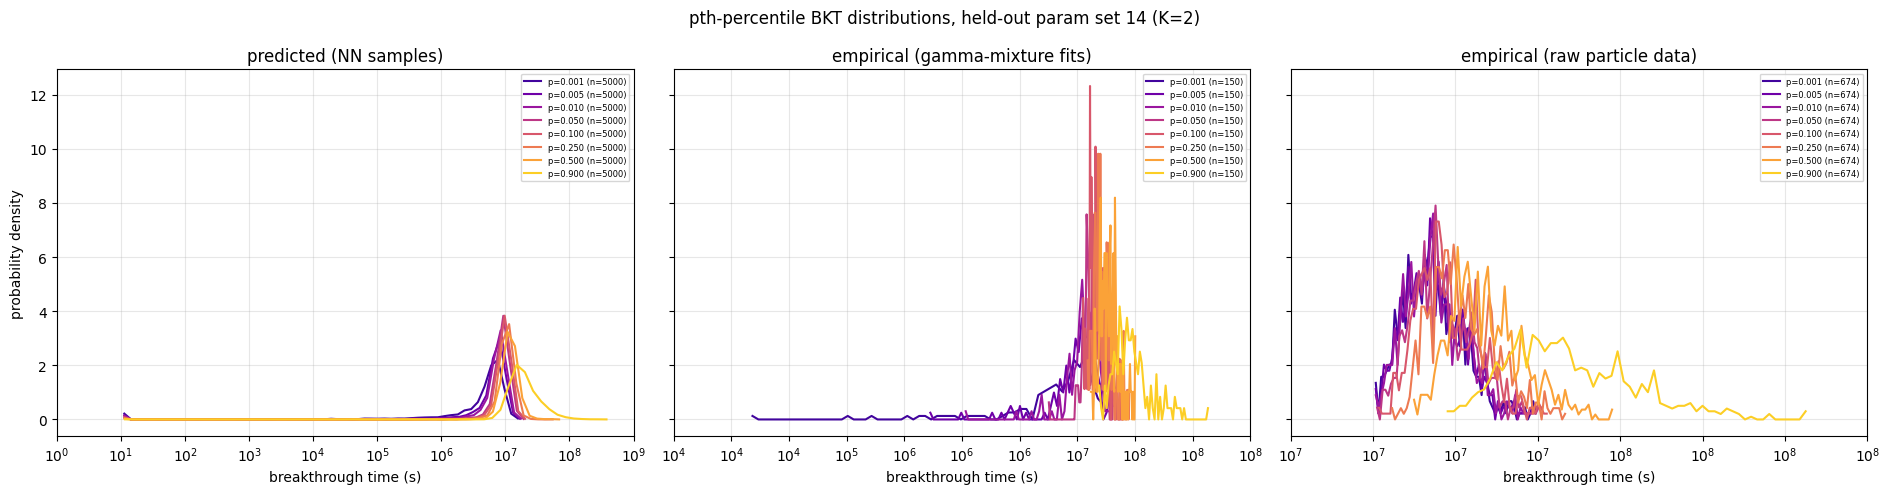

In [16]:
# pth-percentile BKT distributions from sampled coefficients, vs. two different
# empirical baselines, shown as three separate (not overlaid) panels:
#   1. predicted:            NN-sampled coefficients -> gamma-mixture quantile
#   2. empirical (fit-based): each trial's own MLE-fit coefficients -> gamma-mixture quantile
#      (same computation as (1), isolates "are the NN's predicted coefficients good"
#      from "is the gamma-mixture itself a good model of the true BKT distribution")
#   3. empirical (raw):       quantile_bkt on actual particle arrival times, no
#      gamma-mixture involved at all (same quantity as [per p] distrib of pth
#      percentile bkt.ipynb) -- the full end-to-end ground truth

def quantile_bkt(bkt, p, Np):
    """pth-percentile breakthrough time for one trial from its RAW particle
    arrival times (order statistic), or None if undefined. Copied verbatim
    from [per p] distrib of pth percentile bkt.ipynb."""
    k = int(np.floor(p * Np))
    if k < len(bkt):
        return bkt[k]
    return None


def batch_gamma_mixture_quantile(w1, a1, b1, a2, b2, p, t_grid):
    """Vectorized inverse-CDF of a 2-component gamma mixture (no closed form
    exists) via a fine t_grid + linear interpolation. Validated against
    scipy's exact gamma.ppf on a degenerate (single-component) case: <0.06%
    relative error across p in [0.001, 0.9] with a 500-point grid.

    frac is clipped to [0,1] and the result clamped to the grid range -- some
    predicted coefficient draws are extreme enough (e.g. a near-zero-weight
    component saturated entirely below/above the grid) that the local CDF
    slope at the bracketing grid cell is ~0, and unclamped linear
    extrapolation there blows up to +-1e299. Clamping means those cases
    report "quantile is at least/at most the grid edge" rather than garbage."""
    w1, a1, b1, a2, b2 = (np.atleast_1d(x) for x in (w1, a1, b1, a2, b2))
    cdf_grid = (w1[:, None] * gamma_dist.cdf(t_grid[None, :], a=a1[:, None], scale=b1[:, None]) +
                (1 - w1[:, None]) * gamma_dist.cdf(t_grid[None, :], a=a2[:, None], scale=b2[:, None]))
    idx = np.clip(np.sum(cdf_grid < p, axis=1) - 1, 0, len(t_grid) - 2)
    rows = np.arange(len(idx))
    t0, t1 = t_grid[idx], t_grid[idx + 1]
    c0, c1 = cdf_grid[rows, idx], cdf_grid[rows, idx + 1]
    denom = c1 - c0
    frac = np.where(denom > 1e-9, (p - c0) / np.where(denom > 1e-9, denom, 1.0), 0.5)
    frac = np.clip(frac, 0.0, 1.0)
    q = t0 + frac * (t1 - t0)
    return np.clip(q, t_grid[0], t_grid[-1])


PCTL_Np = 1000
p_vals = [0.001, 0.005, 0.01, 0.05, 0.1, 0.25, 0.5, 0.9]
p_colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(p_vals)))
q_grid = np.logspace(1, 9, 500)  # fine grid for the gamma-mixture quantile inversion

# --- source 1: predicted (NN samples) ---
pred_w1 = 1 / (1 + np.exp(-samples[:, 0]))
pred_a1, pred_b1 = np.exp(samples[:, 1]), np.exp(samples[:, 2])
pred_a2, pred_b2 = np.exp(samples[:, 3]), np.exp(samples[:, 4])

# --- source 2: empirical, fit-based (each trial's own MLE-fit coefficients) ---
fit_w1, fit_a1, fit_b1, fit_a2, fit_b2 = (test_df[c].values for c in COEF_NAMES)

# --- source 3: empirical, raw (actual particle arrival times, no gamma-mixture) ---
raw_trial_data = all_param_sets[HELD_OUT_PS]['trial_data']

fig, (ax_pred, ax_fit, ax_raw) = plt.subplots(1, 3, figsize=(19, 5), sharey=True)

for p, color in zip(p_vals, p_colors):
    pred_q = batch_gamma_mixture_quantile(pred_w1, pred_a1, pred_b1, pred_a2, pred_b2, p, q_grid)
    counts, edges = np.histogram(np.log10(pred_q), bins=60, density=True)
    ax_pred.plot((edges[:-1] + edges[1:]) / 2, counts, color=color, label=f'p={p:.3f} (n={len(pred_q)})')

    fit_q = batch_gamma_mixture_quantile(fit_w1, fit_a1, fit_b1, fit_a2, fit_b2, p, q_grid)
    counts, edges = np.histogram(np.log10(fit_q), bins=60, density=True)
    ax_fit.plot((edges[:-1] + edges[1:]) / 2, counts, color=color, label=f'p={p:.3f} (n={len(fit_q)})')

    raw_vals = [quantile_bkt(bkt, p, PCTL_Np) for bkt in raw_trial_data]
    raw_vals = np.array([v for v in raw_vals if v is not None])
    if len(raw_vals) >= 2:
        counts, edges = np.histogram(np.log10(raw_vals), bins=60, density=True)
        ax_raw.plot((edges[:-1] + edges[1:]) / 2, counts, color=color, label=f'p={p:.3f} (n={len(raw_vals)})')

for ax, title in zip((ax_pred, ax_fit, ax_raw),
                     ('predicted (NN samples)',
                      'empirical (gamma-mixture fits)',
                      'empirical (raw particle data)')):
    ax.set_xlabel('breakthrough time (s)')
    ticks = ax.get_xticks()
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'$10^{{{t:.0f}}}$' for t in ticks])
    ax.set_title(title)
    ax.legend(fontsize=6)
    ax.grid(True, alpha=0.3)
ax_pred.set_ylabel('probability density')

plt.suptitle(f'pth-percentile BKT distributions, held-out param set {HELD_OUT_PS} (K={BEST_K})')
plt.tight_layout()
plt.savefig(transport_dir / f'MDN_heldout_ps{HELD_OUT_PS}_K{BEST_K}_percentile_bkt.png', dpi=150)
plt.show()

In [11]:
# --- Conclusion (proof-of-concept, not a production model) ---
#
# The theta-conditioned MDN did NOT beat a theta-blind pooled Gaussian-mixture
# baseline at any K (model held-out NLL 2-10x WORSE than baseline across most
# folds). This is the expected, honest outcome flagged in the plan: with only
# ~6 distinct theta points, there's no way to learn a trustworthy smooth
# theta-dependence -- the shared MLP backbone can only really memorize each
# training group's answer, and extrapolating to a held-out theta (especially
# one far from the training groups in the 3-D theta space) produces an
# overconfident, poorly-calibrated density.
#
# The one partial exception -- param set 14 (best-connected, most samples) --
# came out close to the baseline rather than far worse, and its predicted vs.
# empirical marginals above line up reasonably well. That's the most favorable
# case in this run, not evidence the approach broadly works yet.
#
# Separately, the coefficients themselves show a real data-quality issue worth
# addressing regardless of sample size: alpha2/beta2 span many orders of
# magnitude (up to ~1e13), consistent with the 2nd gamma component being
# poorly identified whenever w1 sits close to 1 (i.e. the fit barely uses that
# component, so its exact shape/scale become nearly unconstrained by the
# likelihood). Worth considering an adaptive single-vs-two-component fit
# rather than always forcing K=2 in fit_gamma_mixture, independent of this
# modeling exercise.
#
# Next step if this direction is worth pursuing further: run a much larger
# param sweep (outputsT_at_varying_parameters.m with many more param sets, and
# probably biased toward theta ranges that stay connected) to get enough
# distinct theta points for a theta-conditioned model to have a chance of
# generalizing -- the pipeline built here (fit -> table -> MDN -> leave-one-
# group-out eval vs. pooled baseline) carries over unchanged to that larger
# dataset.